# Modelado — Predicción de Severidad de Accidentes de Tránsito
**Curso:** Machine Learning Applied — Short-Paper

**Autores:** Jose Muñoz Ríos, Santiago Álvarez Peña

Este notebook contiene el entrenamiento y la evaluación que respaldan las secciones de **Metodología, Resultados y Discusión** del paper. Parte de `cleaned.csv`, que genera `data_s5_eda.ipynb` (22 predictoras + `Accident_severity`: 0 = Fatal, 1 = Serious, 2 = Slight).

Flujo:
1. Grupos de siniestro y partición entrenamiento/prueba **por grupos** (80/20).
2. Preprocesamiento dentro de un `Pipeline` (sin fuga de información).
3. Línea base y búsqueda de hiperparámetros con validación cruzada por grupos (Regresión Logística, Random Forest, Gradient Boosting), optimizando **F1-macro**.
4. Evaluación final en el conjunto de prueba.
5. Entrenamientos **no válidos** como contraste: validación aleatoria (con fuga) y modelos sin ponderación de clases.
6. Figura y tablas del paper (`figuras/`, `resultados/`).

Dependencias: `pandas`, `numpy`, `matplotlib`, `scikit-learn` (≥ 1.4). Tiempo de ejecución aproximado: 10 minutos.

In [1]:
import os, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedGroupKFold, StratifiedKFold, RandomizedSearchCV, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.base import clone
from sklearn.metrics import (accuracy_score, precision_score, balanced_accuracy_score, f1_score, recall_score,
                             roc_auc_score, confusion_matrix, classification_report)
warnings.filterwarnings('ignore', category=UserWarning)
os.makedirs('figuras', exist_ok=True)
os.makedirs('resultados', exist_ok=True)
SEED = 42
CLASES = ['Fatal', 'Serious', 'Slight']

df = pd.read_csv('cleaned.csv')
raw = pd.read_csv('RTA_Dataset.csv')
assert len(df) == len(raw)
X = df.drop(columns='Accident_severity')
y = df['Accident_severity'].to_numpy()
X.shape, np.bincount(y)

((12316, 22), array([  158,  1743, 10415]))

## 1. Grupos de siniestro y partición entrenamiento/prueba

Como se vio en el EDA (sección 2), cada fila es un conductor o vehículo, y varias filas pertenecen al mismo siniestro. Se reconstruye un identificador aproximado de siniestro con las variables del evento del dataset crudo (las filas de `cleaned.csv` están en el mismo orden). La partición se hace con `StratifiedGroupKFold`: todas las filas de un siniestro quedan del mismo lado y se conserva la proporción de clases. Se toma uno de los 5 folds como conjunto de prueba (≈ 20%), que **no se usa** hasta la evaluación final.

In [2]:
cols_evento = ['Time', 'Day_of_week', 'Number_of_vehicles_involved', 'Number_of_casualties',
               'Light_conditions', 'Weather_conditions', 'Road_surface_conditions']
groups = raw.groupby(cols_evento, dropna=False).ngroup().to_numpy()
print('Siniestros aproximados:', len(np.unique(groups)))

outer = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
idx_tr, idx_te = next(outer.split(X, y, groups))
X_tr, X_te, y_tr, y_te = X.iloc[idx_tr], X.iloc[idx_te], y[idx_tr], y[idx_te]
g_tr, g_te = groups[idx_tr], groups[idx_te]
print('Siniestros compartidos entre entrenamiento y prueba:', len(set(g_tr) & set(g_te)))

particion = pd.DataFrame({
    'conjunto': ['Entrenamiento', 'Prueba'],
    'registros': [len(y_tr), len(y_te)],
    'siniestros': [len(np.unique(g_tr)), len(np.unique(g_te))],
    'Fatal': [np.sum(y_tr == 0), np.sum(y_te == 0)],
    'Serious': [np.sum(y_tr == 1), np.sum(y_te == 1)],
    'Slight': [np.sum(y_tr == 2), np.sum(y_te == 2)],
})
particion['%_Fatal'] = (particion['Fatal'] / particion['registros'] * 100).round(1)
particion.to_csv('resultados/particion.csv', index=False)
particion

Siniestros aproximados: 5272


Siniestros compartidos entre entrenamiento y prueba: 0


,conjunto,registros,siniestros,Fatal,Serious,Slight,%_Fatal
0,Entrenamiento,9853,4209,126,1395,8332,1.3
1,Prueba,2463,1063,32,348,2083,1.3


**Observación:** el conjunto de entrenamiento tiene 9,853 registros y el de prueba 2,463 (80/20), sin siniestros compartidos. La proporción de clases se mantiene (≈ 1.3% Fatal en ambos), pero el conjunto de prueba solo tiene **32 registros fatales**: cada uno equivale a ~3 puntos de recall, así que las métricas de esa clase son muy inestables.

## 2. Preprocesamiento

Todo el preprocesamiento vive dentro del `Pipeline`, así que se ajusta solo con los datos de entrenamiento de cada fold:
- **20 variables categóricas** → one-hot; las categorías con menos del 1% de los registros se agrupan en una categoría "infrecuente" (`min_frequency=0.01`), y las no vistas se envían a esa misma categoría.
- **`Hour`** → codificación cíclica (seno y coseno), para que las 23 h y las 0 h queden cerca.
- **`Number_of_vehicles_involved`** → estandarizada.

Desbalance: se usan **pesos por clase** (`class_weight`), que penalizan más los errores en las clases minoritarias sin crear registros sintéticos. El peso se trata como hiperparámetro: `balanced` (inversamente proporcional a la frecuencia; Fatal pesa 66 veces más que Slight) o una versión suavizada con raíz cuadrada (≈ 8 : 2.4 : 1).

In [3]:
cat_cols = X.select_dtypes(exclude='number').columns.tolist()

def hora_ciclica(h):
    h = np.asarray(h, dtype=float)
    return np.c_[np.sin(2 * np.pi * h / 24), np.cos(2 * np.pi * h / 24)]

preproc = ColumnTransformer([
    ('cat', OneHotEncoder(handle_unknown='infrequent_if_exist', min_frequency=0.01, sparse_output=False), cat_cols),
    ('hora', FunctionTransformer(hora_ciclica), ['Hour']),
    ('num', StandardScaler(), ['Number_of_vehicles_involved']),
])
n_feat = preproc.fit(X_tr).transform(X_tr.head()).shape[1]
print('Variables categóricas:', len(cat_cols), '| Columnas tras el preprocesamiento:', n_feat)

conteo = np.bincount(y_tr)
w_bal = len(y_tr) / (3 * conteo)
W_SQRT = {i: round(float(w), 2) for i, w in enumerate(np.sqrt(w_bal / w_bal[2]))}
print('Pesos balanced (relativos a Slight):', np.round(w_bal / w_bal[2], 1))
print('Pesos suavizados (raíz):', W_SQRT)

Variables categóricas: 20 | Columnas tras el preprocesamiento: 141
Pesos balanced (relativos a Slight): [66.1  6.   1. ]
Pesos suavizados (raíz): {0: 8.13, 1: 2.44, 2: 1.0}


## 3. Línea base y búsqueda de hiperparámetros

- **Línea base:** `DummyClassifier` que siempre predice la clase mayoritaria (Slight).
- **Modelos:** Regresión Logística (lineal e interpretable), Random Forest y Histogram Gradient Boosting (no lineales, capturan interacciones).
- **Selección:** `RandomizedSearchCV` con 12 combinaciones por modelo y **validación cruzada de 5 folds por grupos** (`StratifiedGroupKFold`) dentro del conjunto de entrenamiento, optimizando **F1-macro**. El mejor modelo se elige por su F1-macro en validación cruzada, no por el conjunto de prueba.

In [4]:
cv_grupos = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=0)

espacios = {
    'Regresión Logística': (LogisticRegression(max_iter=3000), {
        'clf__C': [0.003, 0.01, 0.03, 0.1, 0.3, 1],
        'clf__class_weight': ['balanced', W_SQRT]}),
    'Random Forest': (RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=SEED), {
        'clf__max_depth': [6, 10, 14, None],
        'clf__min_samples_leaf': [3, 10, 30],
        'clf__max_features': ['sqrt', 0.2],
        'clf__class_weight': ['balanced_subsample', W_SQRT]}),
    'Gradient Boosting': (HistGradientBoostingClassifier(max_iter=300, early_stopping=False, random_state=SEED), {
        'clf__learning_rate': [0.02, 0.05, 0.1],
        'clf__max_depth': [3, 5, None],
        'clf__max_leaf_nodes': [15, 31],
        'clf__l2_regularization': [0, 1],
        'clf__min_samples_leaf': [20, 100],
        'clf__class_weight': ['balanced', W_SQRT]}),
}

busquedas, filas_cv = {}, []
t0 = time.time()
for nombre, (clf, espacio) in espacios.items():
    rs = RandomizedSearchCV(Pipeline([('pre', preproc), ('clf', clf)]), espacio, n_iter=12,
                            scoring='f1_macro', cv=cv_grupos, random_state=0, n_jobs=1)
    rs.fit(X_tr, y_tr, groups=g_tr)
    busquedas[nombre] = rs
    filas_cv.append({'modelo': nombre,
                     'F1-macro CV (media)': rs.best_score_,
                     'F1-macro CV (desv.)': rs.cv_results_['std_test_score'][rs.best_index_],
                     'mejores hiperparámetros': {k.replace('clf__', ''): v for k, v in rs.best_params_.items()}})
    print(f'{nombre}: F1-macro CV = {rs.best_score_:.3f}  ({time.time() - t0:.0f} s)')

base = DummyClassifier(strategy='most_frequent')
base_cv = cross_val_score(base, X_tr, y_tr, groups=g_tr, cv=cv_grupos, scoring='f1_macro')
filas_cv.insert(0, {'modelo': 'Línea base', 'F1-macro CV (media)': base_cv.mean(),
                    'F1-macro CV (desv.)': base_cv.std(), 'mejores hiperparámetros': '-'})
tabla_cv = pd.DataFrame(filas_cv)
tabla_cv.to_csv('resultados/validacion_cruzada.csv', index=False)
tabla_cv.round(3)

Regresión Logística: F1-macro CV = 0.348  (90 s)


Random Forest: F1-macro CV = 0.384  (179 s)


Gradient Boosting: F1-macro CV = 0.367  (411 s)


,modelo,F1-macro CV (media),F1-macro CV (desv.),mejores hiperparámetros
0,Línea base,0.305,0.000,-
1,Regresión Logística,0.348,0.022,"{'class_weight': {0: 8.13, 1: 2.44, 2: 1.0}, '..."
2,Random Forest,0.384,0.018,"{'min_samples_leaf': 10, 'max_features': 0.2, ..."
3,Gradient Boosting,0.367,0.019,"{'min_samples_leaf': 100, 'max_leaf_nodes': 31..."


In [5]:
mejor_nombre = max(busquedas, key=lambda n: busquedas[n].best_score_)
print('Modelo seleccionado por validación cruzada:', mejor_nombre)

Modelo seleccionado por validación cruzada: Random Forest


**Observación:** los tres modelos superan a la línea base en validación cruzada por grupos (F1-macro 0.31), pero con márgenes modestos. **Random Forest** obtiene el mejor F1-macro (≈ 0.38) y se selecciona como modelo final. La Regresión Logística queda por debajo de los modelos de árboles, lo que sugiere que las interacciones entre variables aportan algo de señal. La desviación entre folds (≈ 0.02) es comparable a las diferencias entre modelos, por lo que la ventaja de Random Forest sobre Gradient Boosting es pequeña.

## 4. Evaluación final en el conjunto de prueba

In [6]:
def metricas(nombre, modelo, X_eval=X_te, y_eval=y_te):
    pred = modelo.predict(X_eval)
    rec = recall_score(y_eval, pred, average=None, labels=[0, 1, 2])
    prec = precision_score(y_eval, pred, average=None, labels=[0, 1, 2], zero_division=0)
    fila = {'modelo': nombre,
            'Exactitud': accuracy_score(y_eval, pred),
            'Exactitud balanceada': balanced_accuracy_score(y_eval, pred),
            'F1-macro': f1_score(y_eval, pred, average='macro'),
            'Recall Fatal': rec[0], 'Recall Serious': rec[1], 'Recall Slight': rec[2],
            'Precisión Serious': prec[1]}
    try:
        fila['AUC macro (OvR)'] = roc_auc_score(y_eval, modelo.predict_proba(X_eval), multi_class='ovr', average='macro')
    except Exception:
        fila['AUC macro (OvR)'] = np.nan
    return fila

base.fit(X_tr, y_tr)
filas_test = [metricas('Línea base', base)]
for nombre, rs in busquedas.items():
    filas_test.append(metricas(nombre, rs.best_estimator_))
tabla_test = pd.DataFrame(filas_test)
tabla_test.to_csv('resultados/metricas_prueba.csv', index=False)   # sin redondear
tabla_test.round(3)

,modelo,Exactitud,Exactitud balanceada,F1-macro,Recall Fatal,Recall Serious,Recall Slight,Precisión Serious,AUC macro (OvR)
0,Línea base,0.846,0.333,0.305,0.000,0.000,1.000,0.000,0.500
1,Regresión Logística,0.834,0.357,0.352,0.031,0.063,0.975,0.355,0.575
2,Random Forest,0.741,0.376,0.370,0.000,0.302,0.825,0.234,0.529
3,Gradient Boosting,0.695,0.368,0.353,0.000,0.339,0.765,0.196,0.548


In [7]:
final = busquedas[mejor_nombre].best_estimator_
pred_final = final.predict(X_te)
print(classification_report(y_te, pred_final, target_names=CLASES, digits=3, zero_division=0))
cm = confusion_matrix(y_te, pred_final, labels=[0, 1, 2])
pd.DataFrame(cm, index=[f'real {c}' for c in CLASES], columns=[f'pred {c}' for c in CLASES])

              precision    recall  f1-score   support

       Fatal      0.000     0.000     0.000        32
     Serious      0.234     0.302     0.263       348
      Slight      0.867     0.825     0.846      2083

    accuracy                          0.741      2463
   macro avg      0.367     0.376     0.370      2463
weighted avg      0.766     0.741     0.752      2463



,pred Fatal,pred Serious,pred Slight
real Fatal,0,6,26
real Serious,5,105,238
real Slight,26,338,1719


In [8]:
# AUC por clase (uno contra el resto) del modelo final: capacidad de ordenar por riesgo, sin depender del umbral
proba = final.predict_proba(X_te)
auc_clase = {c: round(roc_auc_score(y_te == k, proba[:, k]), 3) for k, c in enumerate(CLASES)}
print('AUC por clase:', auc_clase)

AUC por clase: {'Fatal': 0.461, 'Serious': 0.553, 'Slight': 0.574}


**Observación:** en el conjunto de prueba, Random Forest alcanza un **F1-macro de ≈ 0.37** frente a 0.31 de la línea base, con exactitud balanceada de ≈ 0.38 (la línea base obtiene 0.33). La mejora proviene casi por completo de la clase **Serious** (recall ≈ 0.30, frente a 0 en la línea base), a costa de clasificar como graves algunos accidentes leves (recall Slight ≈ 0.83). La precisión en Serious es baja (≈ 0.23): de cada 100 registros que el modelo marca como graves, solo unos 23 lo son. La Regresión Logística tiene una exactitud cercana a la de la línea base (0.83) porque casi siempre predice Slight (recall Serious ≈ 0.06), y Gradient Boosting detecta algo más de graves (≈ 0.34) a costa de más falsas alarmas. La clase **Fatal no se detecta**: ninguno de los 32 casos fatales de prueba se clasifica correctamente (26 se predicen como Slight y 6 como Serious). El AUC también es bajo (macro ≈ 0.53; por clase: Fatal 0.46, Serious 0.55, Slight 0.57): el modelo apenas ordena los registros por riesgo mejor que el azar (0.5), y en la clase Fatal ni siquiera lo logra, aunque con 32 casos esa cifra es muy inestable. La exactitud de todos los modelos (≈ 0.70–0.83) es **menor** que la de la línea base (0.85), lo que confirma que la exactitud no sirve para comparar modelos en este problema.

## 5. Entrenamientos no válidos (contraste)

Se reproducen dos errores metodológicos frecuentes para cuantificar su efecto:

**(a) Validación aleatoria (con fuga de información).** Se repite la validación cruzada con `StratifiedKFold`, que ignora los grupos: registros del mismo siniestro quedan en entrenamiento y validación a la vez.

In [9]:
cv_aleatoria = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
filas_fuga = []
for nombre, rs in busquedas.items():
    est = clone(rs.best_estimator_)
    f_grupos = cross_val_score(est, X_tr, y_tr, groups=g_tr, cv=cv_grupos, scoring='f1_macro')
    f_aleat = cross_val_score(est, X_tr, y_tr, cv=cv_aleatoria, scoring='f1_macro')
    filas_fuga.append({'modelo': nombre,
                       'F1-macro CV por grupos (válida)': f_grupos.mean(),
                       'F1-macro CV aleatoria (no válida)': f_aleat.mean(),
                       'sobreestimación': f_aleat.mean() - f_grupos.mean()})
tabla_fuga = pd.DataFrame(filas_fuga)
tabla_fuga.to_csv('resultados/fuga_validacion.csv', index=False)
tabla_fuga.round(3)

,modelo,F1-macro CV por grupos (válida),F1-macro CV aleatoria (no válida),sobreestimación
0,Regresión Logística,0.348,0.336,-0.012
1,Random Forest,0.384,0.440,0.057
2,Gradient Boosting,0.367,0.447,0.079


**Observación:** la validación aleatoria **sobreestima** el F1-macro de los modelos de árboles en 6 a 8 puntos (Random Forest: 0.384 → 0.440; Gradient Boosting: 0.367 → 0.447), porque el modelo "reconoce" en validación siniestros que ya vio en entrenamiento. La Regresión Logística, menos flexible, no se ve afectada (incluso baja levemente). Con una validación aleatoria se habrían reportado resultados más optimistas de lo que el modelo logra con siniestros nuevos.

**(b) Entrenamiento sin ponderar las clases.** Se reentrenan los modelos con los mismos hiperparámetros, pero sin `class_weight`.

In [10]:
filas_sin_peso = []
for nombre, rs in busquedas.items():
    est = clone(rs.best_estimator_).set_params(clf__class_weight=None)
    est.fit(X_tr, y_tr)
    filas_sin_peso.append(metricas(nombre + ' (sin pesos)', est))
tabla_sin_peso = pd.DataFrame(filas_sin_peso)
tabla_sin_peso.to_csv('resultados/sin_pesos.csv', index=False)
tabla_sin_peso.round(3)

,modelo,Exactitud,Exactitud balanceada,F1-macro,Recall Fatal,Recall Serious,Recall Slight,Precisión Serious,AUC macro (OvR)
0,Regresión Logística (sin pesos),0.846,0.333,0.305,0.0,0.000,1.000,0.00,0.585
1,Random Forest (sin pesos),0.846,0.333,0.305,0.0,0.000,1.000,0.00,0.566
2,Gradient Boosting (sin pesos),0.834,0.341,0.329,0.0,0.046,0.978,0.25,0.534


**Observación:** sin pesos por clase, los modelos colapsan hacia la clase mayoritaria: la exactitud sube a 0.83–0.85 (igual o casi igual a la línea base), pero el recall de Serious y Fatal cae a prácticamente cero (≤ 0.05) y el F1-macro queda en el nivel de la línea base o muy cerca (≤ 0.33). Regresión Logística y Random Forest predicen *Slight* para todos los registros. Es el caso típico en que un modelo "bueno" según la exactitud no sirve para el objetivo del proyecto.

## 6. Figura del paper

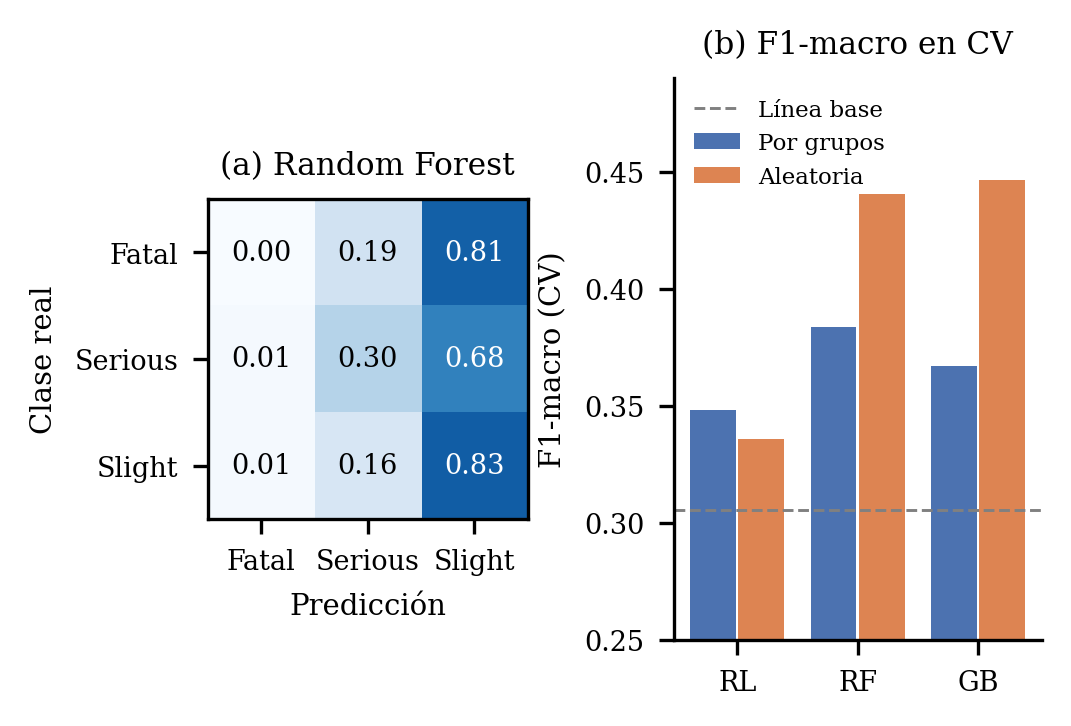

In [11]:
plt.rcParams.update({'font.family': 'serif', 'font.size': 7, 'axes.titlesize': 7.5,
                     'axes.labelsize': 7, 'xtick.labelsize': 6.5, 'ytick.labelsize': 6.5})
fig, axes = plt.subplots(1, 2, figsize=(3.45, 2.3), dpi=300, gridspec_kw={'width_ratios': [1, 1.15]})

# (a) matriz de confusión normalizada por clase real
ax = axes[0]
cm_norm = cm / cm.sum(axis=1, keepdims=True)
ax.imshow(cm_norm, cmap='Blues', vmin=0, vmax=1)
for i in range(3):
    for j in range(3):
        ax.text(j, i, f'{cm_norm[i, j]:.2f}', ha='center', va='center', fontsize=6.5,
                color='white' if cm_norm[i, j] > 0.5 else 'black')
ax.set_xticks(range(3), ['Fatal', 'Serious', 'Slight'])
ax.set_yticks(range(3), ['Fatal', 'Serious', 'Slight'])
ax.set_xlabel('Predicción')
ax.set_ylabel('Clase real')
ax.set_title('(a) Random Forest')

# (b) F1-macro: validación por grupos vs aleatoria
ax = axes[1]
etiquetas = ['RL', 'RF', 'GB']
xpos = np.arange(len(etiquetas))
ax.bar(xpos - 0.2, tabla_fuga['F1-macro CV por grupos (válida)'], 0.38, color='#4C72B0', label='Por grupos')
ax.bar(xpos + 0.2, tabla_fuga['F1-macro CV aleatoria (no válida)'], 0.38, color='#DD8452', label='Aleatoria')
ax.axhline(base_cv.mean(), color='gray', ls='--', lw=0.7, label='Línea base')
ax.set_xticks(xpos, etiquetas)
ax.set_ylim(0.25, 0.49)
ax.set_ylabel('F1-macro (CV)')
ax.set_title('(b) F1-macro en CV')
ax.legend(fontsize=5.5, frameon=False, loc='upper left')
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout(pad=0.4)
fig.savefig('figuras/fig3_resultados.png', dpi=300)
plt.show()
plt.rcParams.update(plt.rcParamsDefault)

**Observación:** (a) en la matriz de confusión del modelo final, el 81% de los casos fatales se clasifica como Slight y el 19% como Serious; Serious se detecta en el 30% de los casos y Slight en el 83%. (b) La validación aleatoria (naranja) da valores de F1-macro más altos que la validación por grupos (azul) en los modelos de árboles; la línea punteada es la línea base.

## 7. Conclusiones del modelado

- Con validación por grupos de siniestro, el mejor modelo (**Random Forest** con pesos por clase) supera a la línea base en F1-macro (≈ 0.37 frente a 0.31 en prueba), pero la mejora es modesta y se concentra en la clase Serious.
- La clase **Fatal no se logra detectar** con estas variables y 126 ejemplos de entrenamiento.
- Validar de forma aleatoria sobreestima el desempeño, y entrenar sin ponderar las clases produce modelos que solo predicen la clase mayoritaria: ambos son errores que invalidarían las conclusiones.